In [4]:
import sys
print(sys.version)

import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

import pgmpy
print("pgmpy:", pgmpy.__version__)

3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Pandas: 3.0.3
NumPy: 2.4.6
pgmpy: 1.1.2


In [5]:
df = pd.read_csv(r"C:\Users\DELL\Documents\project_folder_sem5\probablity_project\Crop_recommendation_cleaned (1).csv")

print("Shape:", df.shape)
display(df.head())

print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCrop classes:")
print(df["label"].value_counts())

Shape: (2200, 8)


,n,p,k,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   n            2200 non-null   int64  
 1   p            2200 non-null   int64  
 2   k            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB
None

Missing values:
n              0
p              0
k              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Crop classes:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango

In [6]:
display(df.describe())

,n,p,k,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


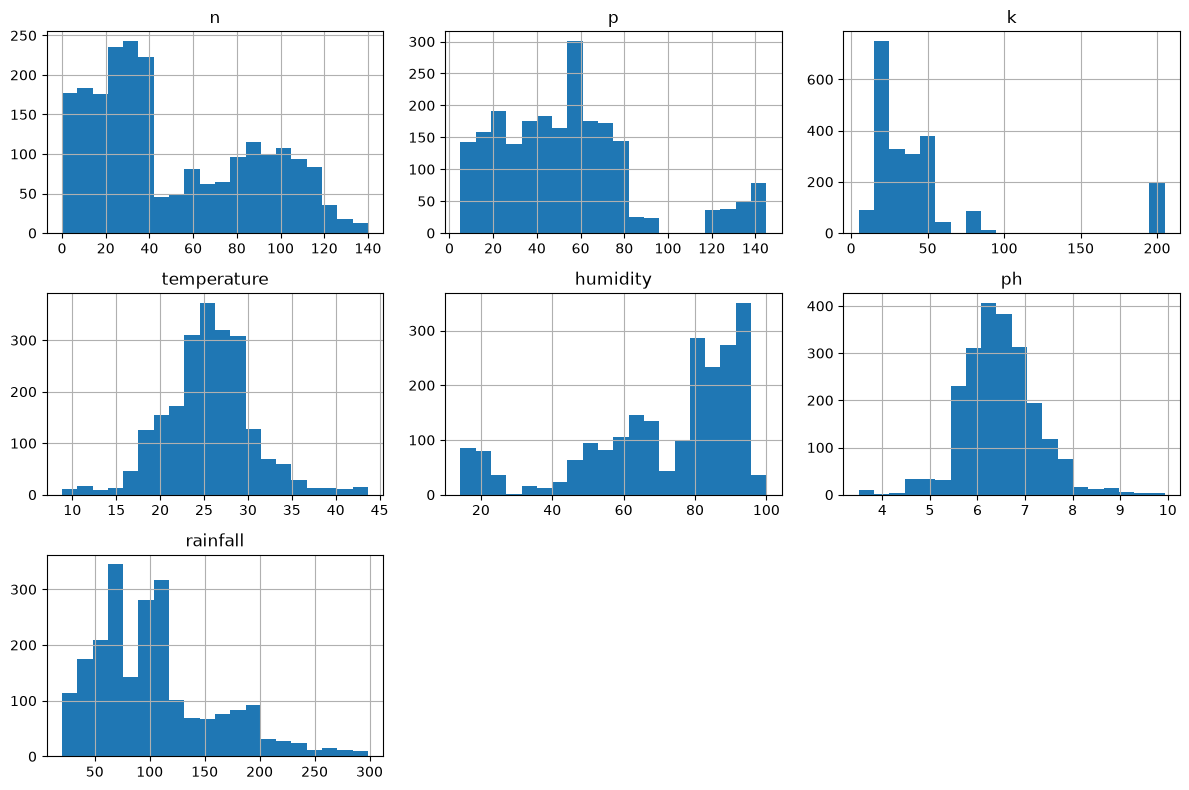

In [7]:
import matplotlib.pyplot as plt

features = ['n', 'p', 'k', 'temperature', 'humidity', 'ph', 'rainfall']

df[features].hist(figsize=(12, 8), bins=20)

plt.tight_layout()
plt.show()

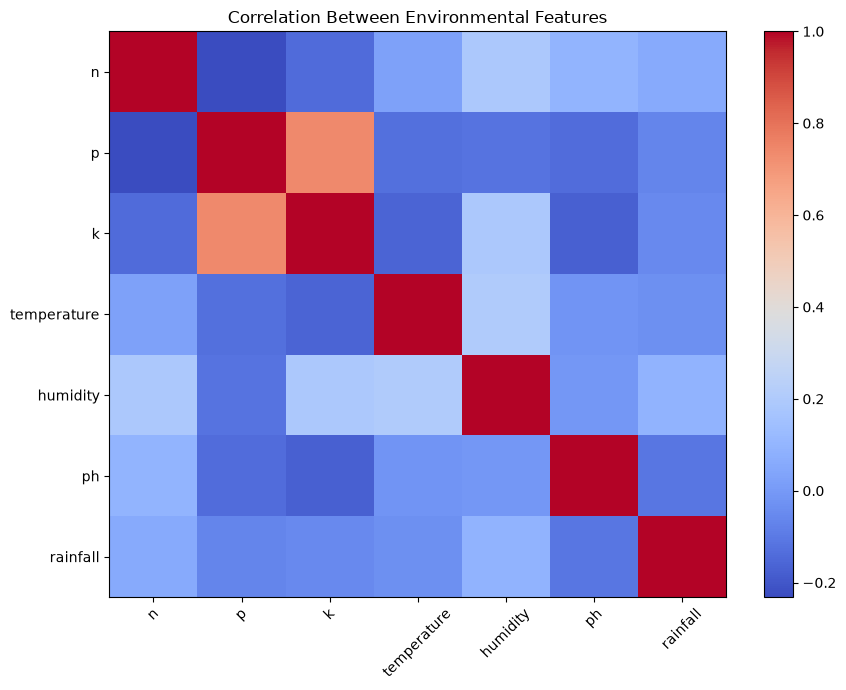

,n,p,k,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.630942,92.333383,5.929663,112.654779
banana,100.23,82.01,50.05,27.376798,80.358123,5.983893,104.626980
blackgram,40.02,67.47,19.24,29.973340,65.118426,7.133952,67.884151
chickpea,40.09,67.79,79.92,18.872847,16.860439,7.336957,80.058977
coconut,21.98,16.93,30.59,27.409892,94.844272,5.976562,175.686646
coffee,101.20,28.74,29.94,25.540477,58.869846,6.790308,158.066295
cotton,117.77,46.24,19.56,23.988958,79.843474,6.912675,80.398043
grapes,23.18,132.53,200.11,23.849575,81.875228,6.025937,69.611829
jute,78.40,46.86,39.99,24.958376,79.639864,6.732778,174.792798


In [8]:
corr = df[features].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap='coolwarm', aspect='auto')
plt.colorbar()

plt.xticks(range(len(features)), features, rotation=45)
plt.yticks(range(len(features)), features)

plt.title("Correlation Between Environmental Features")
plt.tight_layout()
plt.show()


crop_summary = df.groupby('label')[features].mean()

display(crop_summary)

In [9]:
from sklearn.model_selection import train_test_split

X = df[features].copy()
y = df['label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1760
Testing samples: 440


In [10]:


X_train_disc = X_train.copy()
X_test_disc = X_test.copy()

bin_edges = {}

for col in features:
    _, edges = pd.qcut(
        X_train[col],
        q=3,
        retbins=True,
        duplicates='drop'
    )

    edges[0] = -np.inf
    edges[-1] = np.inf
    bin_edges[col] = edges

    X_train_disc[col] = pd.cut(
        X_train[col],
        bins=edges,
        labels=['Low', 'Medium', 'High'],
        include_lowest=True
    )

    X_test_disc[col] = pd.cut(
        X_test[col],
        bins=edges,
        labels=['Low', 'Medium', 'High'],
        include_lowest=True
    )

print("Discretization completed.")

for col in features:
    print("\n", col)
    print(X_train_disc[col].value_counts())

Discretization completed.

 n
n
Low       611
High      584
Medium    565
Name: count, dtype: int64

 p
p
Low       603
Medium    585
High      572
Name: count, dtype: int64

 k
k
Low       629
High      577
Medium    554
Name: count, dtype: int64

 temperature
temperature
Low       587
High      587
Medium    586
Name: count, dtype: int64

 humidity
humidity
Low       587
High      587
Medium    586
Name: count, dtype: int64

 ph
ph
Low       587
High      587
Medium    586
Name: count, dtype: int64

 rainfall
rainfall
Low       587
High      587
Medium    586
Name: count, dtype: int64


In [11]:
train_bn = X_train_disc.copy()
test_bn = X_test_disc.copy()

train_bn['label'] = y_train.values
test_bn['label'] = y_test.values

print(train_bn.head())

           n       p       k temperature humidity      ph rainfall  \
1607     Low     Low     Low        High     High    High     High   
1212     Low    High    High        High   Medium     Low      Low   
362      Low    High  Medium         Low      Low     Low     High   
566   Medium  Medium     Low      Medium      Low  Medium      Low   
1671     Low     Low     Low         Low     High  Medium     High   

            label  
1607       orange  
1212       grapes  
362   kidneybeans  
566     mothbeans  
1671       orange  


In [12]:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, BDeu, BayesianEstimator, ExpertKnowledge

# Structure Learning using Hill Climbing + BDeu

# Learn relationships from data while preventing label -> feature edges
forbidden_edges = [('label', feature) for feature in features]
expert_knowledge = ExpertKnowledge(forbidden_edges=forbidden_edges)

structure_learner = HillClimbSearch(train_bn)
learned_structure = structure_learner.estimate(
    scoring_method=BDeu(train_bn, equivalent_sample_size=10),
    expert_knowledge=expert_knowledge
)

print("Structure learning completed.")
print("\nLearned Bayesian Network edges:")
for edge in learned_structure.edges():
    print(edge)

# Include all variables, even if a variable has no learned edges
model_bn = DiscreteBayesianNetwork()
model_bn.add_nodes_from(train_bn.columns)
model_bn.add_edges_from(learned_structure.edges())

print("\nNumber of learned edges:", len(model_bn.edges()))

# Bayesian Parameter Learning
bayesian_estimator = BayesianEstimator(model_bn, train_bn)
cpds = bayesian_estimator.get_parameters(
    prior_type='dirichlet',
    pseudo_counts=0.1
)
model_bn.add_cpds(*cpds)

print("\nNumber of CPDs:", len(model_bn.get_cpds()))
print("Model valid:", model_bn.check_model())
print("\nBayesian parameter learning completed.")


C:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (
C:\Users\DELL\AppData\Local\Temp\ipykernel_2124\2081797240.py:10: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  structure_learner = HillClimbSearch(train_bn)


  0%|          | 0/1000000 [00:00<?, ?it/s]

Structure learning completed.

Learned Bayesian Network edges:
('n', 'humidity')
('n', 'temperature')
('n', 'k')
('p', 'label')
('p', 'k')
('p', 'humidity')
('p', 'n')
('p', 'rainfall')
('k', 'label')
('k', 'temperature')
('k', 'ph')
('humidity', 'label')
('humidity', 'k')
('humidity', 'temperature')
('humidity', 'ph')
('rainfall', 'label')
('rainfall', 'k')
('rainfall', 'humidity')
('rainfall', 'n')
('rainfall', 'ph')
('rainfall', 'temperature')

Number of learned edges: 21

Number of CPDs: 8
Model valid: True

Bayesian parameter learning completed.


C:\Users\DELL\AppData\Local\Temp\ipykernel_2124\2081797240.py:29: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  bayesian_estimator = BayesianEstimator(model_bn, train_bn)


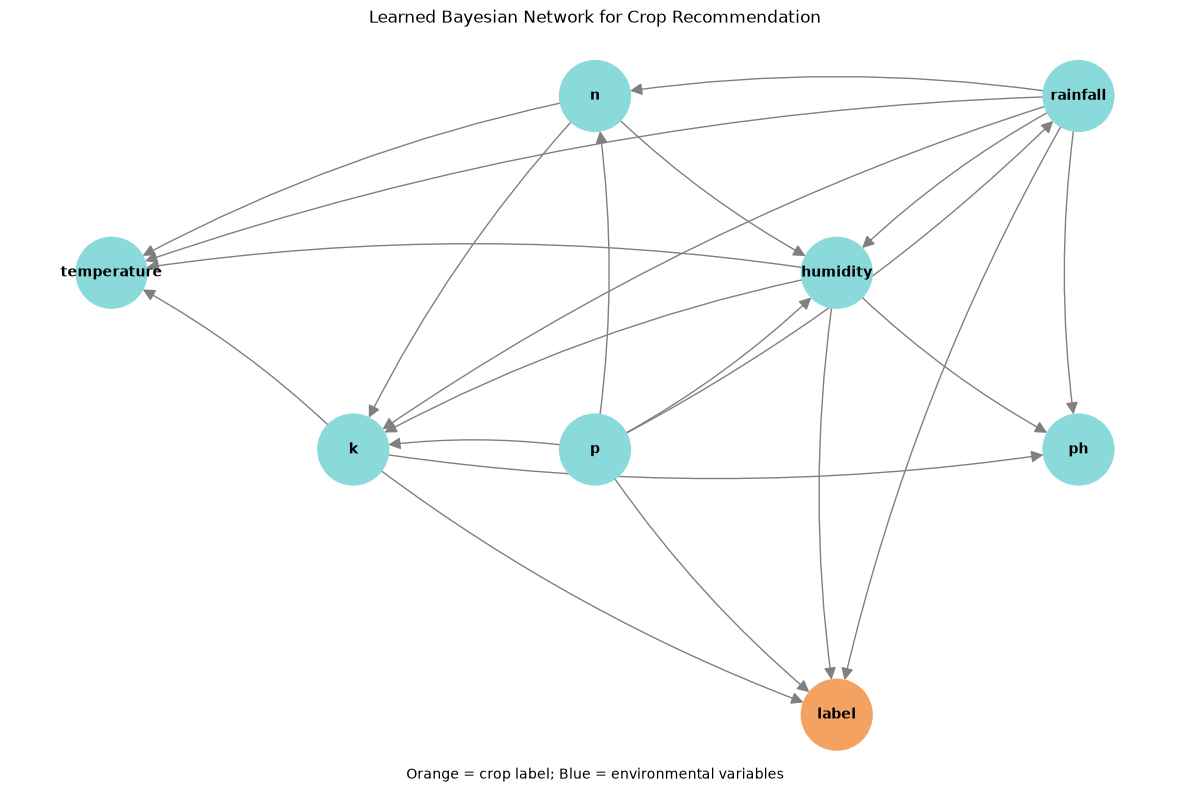

Parents of label: ['p', 'k', 'humidity', 'rainfall']
Children of label: []

Learned environmental dependencies:
n -> humidity
n -> temperature
n -> k
p -> k
p -> humidity
p -> n
p -> rainfall
k -> temperature
k -> ph
humidity -> k
humidity -> temperature
humidity -> ph
rainfall -> k
rainfall -> humidity
rainfall -> n
rainfall -> ph
rainfall -> temperature


In [13]:

import networkx as nx
import matplotlib.pyplot as plt

# Visualize the structure learned from the training dataset
G = nx.DiGraph()
G.add_nodes_from(train_bn.columns)
G.add_edges_from(model_bn.edges())


# Arrange nodes in fixed positions for a clearer graph
pos = {
    'n': (0, 2),
    'temperature': (-2, 1),
    'rainfall': (2, 2),
    'humidity': (1, 1),
    'p': (0, 0),
    'k': (-1, 0),
    'ph': (2, 0),
    'label': (1, -1.5)
}

node_colors = [
    '#F4A261' if node == 'label' else '#8ADADC'
    for node in G.nodes()
]

plt.figure(figsize=(12, 8))
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2600,
    font_size=10,
    font_weight='bold',
    arrows=True,
    arrowsize=18,
    edge_color='gray',
    connectionstyle='arc3,rad=0.08'
)

plt.title('Learned Bayesian Network for Crop Recommendation')
plt.figtext(
    0.5, 0.02,
    'Orange = crop label; Blue = environmental variables',
    ha='center'
)
plt.axis('off')
plt.tight_layout()
plt.show()


# Inspect direct relationships involving the crop label
print("Parents of label:", list(G.predecessors('label')))
print("Children of label:", list(G.successors('label')))

print("\nLearned environmental dependencies:")
for source, target in G.edges():
    if source != 'label' and target != 'label':
        print(f"{source} -> {target}")


In [14]:

# Dataset Dependency Analysis
import pandas as pd
from sklearn.metrics import normalized_mutual_info_score

feature_cols = [col for col in train_bn.columns if col != 'label']

# Pairwise dependency strength between discretized environmental variables
dependency_matrix = pd.DataFrame(
    index=feature_cols, columns=feature_cols, dtype=float
)

for a in feature_cols:
    for b in feature_cols:
        dependency_matrix.loc[a, b] = normalized_mutual_info_score(
            train_bn[a], train_bn[b]
        )

print("Pairwise normalized mutual information:")
display(dependency_matrix.round(3))

# Rank the strongest environmental dependencies
pairs = []
for i, a in enumerate(feature_cols):
    for b in feature_cols[i + 1:]:
        pairs.append({
            'Feature 1': a,
            'Feature 2': b,
            'Normalized MI': dependency_matrix.loc[a, b]
        })

dependency_ranking = pd.DataFrame(pairs).sort_values(
    'Normalized MI', ascending=False
)

print("\nStrongest environmental dependencies:")
display(dependency_ranking.head(10).round(3))

# Association of each environmental variable with the crop label
label_associations = pd.DataFrame([
    {
        'Feature': col,
        'Normalized MI with label': normalized_mutual_info_score(
            train_bn[col], train_bn['label']
        )
    }
    for col in feature_cols
]).sort_values('Normalized MI with label', ascending=False)

print("\nEnvironmental features associated with crop label:")
display(label_associations.round(3))


Pairwise normalized mutual information:


,n,p,k,temperature,humidity,ph,rainfall
n,1.000,0.047,0.048,0.051,0.076,0.021,0.005
p,0.047,1.000,0.147,0.025,0.092,0.021,0.008
k,0.048,0.147,1.000,0.010,0.057,0.017,0.093
temperature,0.051,0.025,0.010,1.000,0.022,0.004,0.043
humidity,0.076,0.092,0.057,0.022,1.000,0.024,0.012
ph,0.021,0.021,0.017,0.004,0.024,1.000,0.022
rainfall,0.005,0.008,0.093,0.043,0.012,0.022,1.000



Strongest environmental dependencies:


,Feature 1,Feature 2,Normalized MI
6,p,k,0.147
14,k,rainfall,0.093
8,p,humidity,0.092
3,n,humidity,0.076
12,k,humidity,0.057
2,n,temperature,0.051
1,n,k,0.048
0,n,p,0.047
17,temperature,rainfall,0.043
7,p,temperature,0.025



Environmental features associated with crop label:


,Feature,Normalized MI with label
2,k,0.438
4,humidity,0.422
1,p,0.380
6,rainfall,0.353
0,n,0.310
3,temperature,0.243
5,ph,0.156


In [15]:
print("Number of CPDs:", len(model_bn.get_cpds()))
print("Model valid:", model_bn.check_model())

Number of CPDs: 8
Model valid: True


In [16]:
from pgmpy.inference import VariableElimination

inference = VariableElimination(model_bn)

print("Inference engine created.")

Inference engine created.


In [20]:
sample = test_bn.iloc[0]

print(sample)

n                 Low
p                 Low
k                 Low
temperature    Medium
humidity         High
ph               High
rainfall       Medium
label          orange
Name: 1609, dtype: str


In [21]:
evidence = {
    'n': sample['n'],
    'p': sample['p'],
    'k': sample['k'],
    'temperature': sample['temperature'],
    'humidity': sample['humidity'],
    'ph': sample['ph'],
    'rainfall': sample['rainfall']
}

print("Evidence:")
print(evidence)

print("\nActual crop:", sample['label'])

Evidence:
{'n': 'Low', 'p': 'Low', 'k': 'Low', 'temperature': 'Medium', 'humidity': 'High', 'ph': 'High', 'rainfall': 'Medium'}

Actual crop: orange


In [22]:
result = inference.query(
    variables=['label'],
    evidence=evidence
)

print(result)

+--------------------+--------------+
| label              |   phi(label) |
+====================+==============+
| label(apple)       |       0.0026 |
+--------------------+--------------+
| label(banana)      |       0.0026 |
+--------------------+--------------+
| label(blackgram)   |       0.0026 |
+--------------------+--------------+
| label(chickpea)    |       0.0026 |
+--------------------+--------------+
| label(coconut)     |       0.0026 |
+--------------------+--------------+
| label(coffee)      |       0.0026 |
+--------------------+--------------+
| label(cotton)      |       0.0026 |
+--------------------+--------------+
| label(grapes)      |       0.0026 |
+--------------------+--------------+
| label(jute)        |       0.0026 |
+--------------------+--------------+
| label(kidneybeans) |       0.0026 |
+--------------------+--------------+
| label(lentil)      |       0.0026 |
+--------------------+--------------+
| label(maize)       |       0.0026 |
+-----------

In [23]:
probabilities = pd.Series(
    result.values,
    index=result.state_names['label']
)

probabilities = probabilities.sort_values(
    ascending=False
)

display(probabilities.head(10))

orange       0.945026
apple        0.002618
blackgram    0.002618
chickpea     0.002618
coconut      0.002618
banana       0.002618
coffee       0.002618
cotton       0.002618
jute         0.002618
grapes       0.002618
dtype: float64

In [24]:
correct = 0
predictions = []

for _, sample in test_bn.iterrows():

    evidence = {
        'n': sample['n'],
        'p': sample['p'],
        'k': sample['k'],
        'temperature': sample['temperature'],
        'humidity': sample['humidity'],
        'ph': sample['ph'],
        'rainfall': sample['rainfall']
    }

    result = inference.query(
        variables=['label'],
        evidence=evidence,
        show_progress=False
    )

    probabilities = pd.Series(
        result.values,
        index=result.state_names['label']
    )

    predicted_crop = probabilities.idxmax()
    actual_crop = sample['label']

    predictions.append({
        'actual': actual_crop,
        'predicted': predicted_crop,
        'confidence': probabilities.max()
    })

    if predicted_crop == actual_crop:
        correct += 1

accuracy = correct / len(test_bn)

print("Test samples:", len(test_bn))
print("Correct predictions:", correct)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Test samples: 440
Correct predictions: 333
Accuracy: 0.7568181818181818
Accuracy (%): 75.68181818181819


In [25]:
from sklearn.metrics import classification_report

y_true = [x['actual'] for x in predictions]
y_pred = [x['predicted'] for x in predictions]

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

       apple       0.74      1.00      0.85        20
      banana       0.74      1.00      0.85        20
   blackgram       0.11      0.05      0.07        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.77      1.00      0.87        20
      coffee       0.95      1.00      0.98        20
      cotton       0.54      0.70      0.61        20
      grapes       1.00      0.65      0.79        20
        jute       0.80      0.40      0.53        20
 kidneybeans       0.67      0.30      0.41        20
      lentil       0.48      0.60      0.53        20
       maize       0.67      0.20      0.31        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.68      0.95      0.79        20
    mungbean       0.66      0.95      0.78        20
   muskmelon       0.74      1.00      0.85        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [26]:
def get_crop_probabilities(evidence):
    """
    Performs Bayesian inference for the given environmental evidence
    and returns crop probabilities in descending order.
    """
    
    result = inference.query(
        variables=['label'],
        evidence=evidence,
        show_progress=False
    )

    probabilities = pd.Series(
        result.values,
        index=result.state_names['label']
    )

    return probabilities.sort_values(ascending=False)

In [27]:
baseline_evidence = {
    'n': 'Medium',
    'p': 'High',
    'k': 'Medium',
    'temperature': 'High',
    'humidity': 'Low',
    'ph': 'Medium',
    'rainfall': 'Medium'
}

baseline_probs = get_crop_probabilities(baseline_evidence)

print("Baseline Evidence:")
print(baseline_evidence)
print("\nTop 5 Crops:")
display(baseline_probs.head(5))

Baseline Evidence:
{'n': 'Medium', 'p': 'High', 'k': 'Medium', 'temperature': 'High', 'humidity': 'Low', 'ph': 'Medium', 'rainfall': 'Medium'}

Top 5 Crops:


kidneybeans    0.430556
blackgram      0.152778
pigeonpeas     0.152778
chickpea       0.013889
banana         0.013889
dtype: float64

In [29]:
def run_scenarios(base_evidence, variable, states):
    """
    Changes one variable across different states
    while keeping all other evidence fixed.
    """

    results = {}

    for state in states:
        scenario = base_evidence.copy()
        scenario[variable] = state

        results[state] = get_crop_probabilities(scenario)

    return pd.DataFrame(results)

In [31]:
# Rainfall scenario

rainfall_scenarios = run_scenarios(
    baseline_evidence,
    'rainfall',
    ['Low', 'Medium', 'High']
)

display(
    rainfall_scenarios
    .sort_values(by='High', ascending=False)
    .head(10)
)

,Low,Medium,High
pigeonpeas,0.008197,0.152778,0.663934
kidneybeans,0.254098,0.430556,0.172131
blackgram,0.336066,0.152778,0.008197
chickpea,0.008197,0.013889,0.008197
apple,0.008197,0.013889,0.008197
banana,0.008197,0.013889,0.008197
coffee,0.008197,0.013889,0.008197
coconut,0.008197,0.013889,0.008197
grapes,0.008197,0.013889,0.008197
cotton,0.008197,0.013889,0.008197


In [32]:
# Entropy-based uncertainty analysis for rainfall scenarios

uncertainty_results = []

for scenario_name in rainfall_scenarios.columns:
    probabilities = rainfall_scenarios[scenario_name].to_numpy()
    probabilities = probabilities[probabilities > 0]

    # Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    # Normalize entropy to a 0–1 scale for 22 crop classes
    normalized_entropy = entropy / np.log(22)

    scenario_probs = rainfall_scenarios[scenario_name]
    top_crop = scenario_probs.idxmax()
    top_probability = scenario_probs.max()

    uncertainty_results.append({
        'Rainfall Scenario': scenario_name,
        'Top Crop': top_crop,
        'Top Crop Probability (%)': round(top_probability * 100, 2),
        'Entropy': round(entropy, 4),
        'Normalized Uncertainty': round(normalized_entropy, 4)
    })

uncertainty_df = pd.DataFrame(uncertainty_results)

print("Crop Recommendation Uncertainty by Rainfall Scenario")
display(uncertainty_df)

Crop Recommendation Uncertainty by Rainfall Scenario


,Rainfall Scenario,Top Crop,Top Crop Probability (%),Entropy,Normalized Uncertainty
0,Low,blackgram,33.61,1.8109,0.5858
1,Medium,kidneybeans,43.06,2.0655,0.6682
2,High,pigeonpeas,66.39,1.3623,0.4407


In [33]:

# Sensitivity Analysis Across All Environmental Features

sensitivity_results = []
sensitivity_distributions = {}

for feature in features:
    # Change only this feature; keep all other evidence fixed
    scenario_probs = run_scenarios(
        baseline_evidence,
        feature,
        ['Low', 'Medium', 'High']
    )

    sensitivity_distributions[feature] = scenario_probs
    reference_state = baseline_evidence[feature]
    reference_probs = scenario_probs[reference_state]

    entropy_values = {}
    top_crops = {}
    probability_changes = []

    for state in ['Low', 'Medium', 'High']:
        probs = scenario_probs[state]
        probs = probs / probs.sum()

        # Normalized Shannon entropy
        positive_probs = probs[probs > 0]
        entropy = -np.sum(positive_probs * np.log(positive_probs))
        entropy_values[state] = entropy / np.log(len(probs))

        top_crops[state] = probs.idxmax()

        # Total variation distance from the baseline state
        reference = reference_probs.reindex(probs.index, fill_value=0)
        probability_changes.append(
            0.5 * np.abs(probs - reference).sum()
        )

    sensitivity_results.append({
        'Feature': feature,
        'Baseline State': reference_state,
        'Low Top Crop': top_crops['Low'],
        'Medium Top Crop': top_crops['Medium'],
        'High Top Crop': top_crops['High'],
        'Max Probability Distribution Change': max(probability_changes),
        'Low Uncertainty': entropy_values['Low'],
        'Medium Uncertainty': entropy_values['Medium'],
        'High Uncertainty': entropy_values['High']
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df = sensitivity_df.sort_values(
    'Max Probability Distribution Change',
    ascending=False
).reset_index(drop=True)

print("Environmental Feature Sensitivity Analysis")
print("Higher distribution change means greater sensitivity to that feature.")
display(sensitivity_df.round(4))


Environmental Feature Sensitivity Analysis
Higher distribution change means greater sensitivity to that feature.


,Feature,Baseline State,Low Top Crop,Medium Top Crop,High Top Crop,Max Probability Distribution Change,Low Uncertainty,Medium Uncertainty,High Uncertainty
0,p,High,mango,mango,kidneybeans,0.9578,0.0695,0.4859,0.6682
1,k,Medium,kidneybeans,kidneybeans,chickpea,0.9459,0.4042,0.6682,0.0942
2,humidity,Low,kidneybeans,blackgram,apple,0.5997,0.6682,0.8546,1.0000
3,rainfall,Medium,blackgram,kidneybeans,pigeonpeas,0.5112,0.5858,0.6682,0.4407
4,n,Medium,kidneybeans,kidneybeans,kidneybeans,0.0000,0.6682,0.6682,0.6682
5,temperature,High,kidneybeans,kidneybeans,kidneybeans,0.0000,0.6682,0.6682,0.6682
6,ph,Medium,kidneybeans,kidneybeans,kidneybeans,0.0000,0.6682,0.6682,0.6682


In [34]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average='macro')
weighted_f1 = f1_score(y_true, y_pred, average='weighted')

print("Bayesian Network Evaluation")
print("---------------------------")
print(f"Test Samples       : {len(y_true)}")
print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Macro F1 Score     : {macro_f1:.2f}")
print(f"Weighted F1 Score  : {weighted_f1:.2f}")

Bayesian Network Evaluation
---------------------------
Test Samples       : 440
Accuracy           : 75.68%
Macro F1 Score     : 0.73
Weighted F1 Score  : 0.73


Per-Class Performance:
              precision    recall  f1-score   support

       apple       0.74      1.00      0.85        20
      banana       0.74      1.00      0.85        20
   blackgram       0.11      0.05      0.07        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.77      1.00      0.87        20
      coffee       0.95      1.00      0.98        20
      cotton       0.54      0.70      0.61        20
      grapes       1.00      0.65      0.79        20
        jute       0.80      0.40      0.53        20
 kidneybeans       0.67      0.30      0.41        20
      lentil       0.48      0.60      0.53        20
       maize       0.67      0.20      0.31        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.68      0.95      0.79        20
    mungbean       0.66      0.95      0.78        20
   muskmelon       0.74      1.00      0.85        20
      orange       1.00      1.00      1.00        20
    

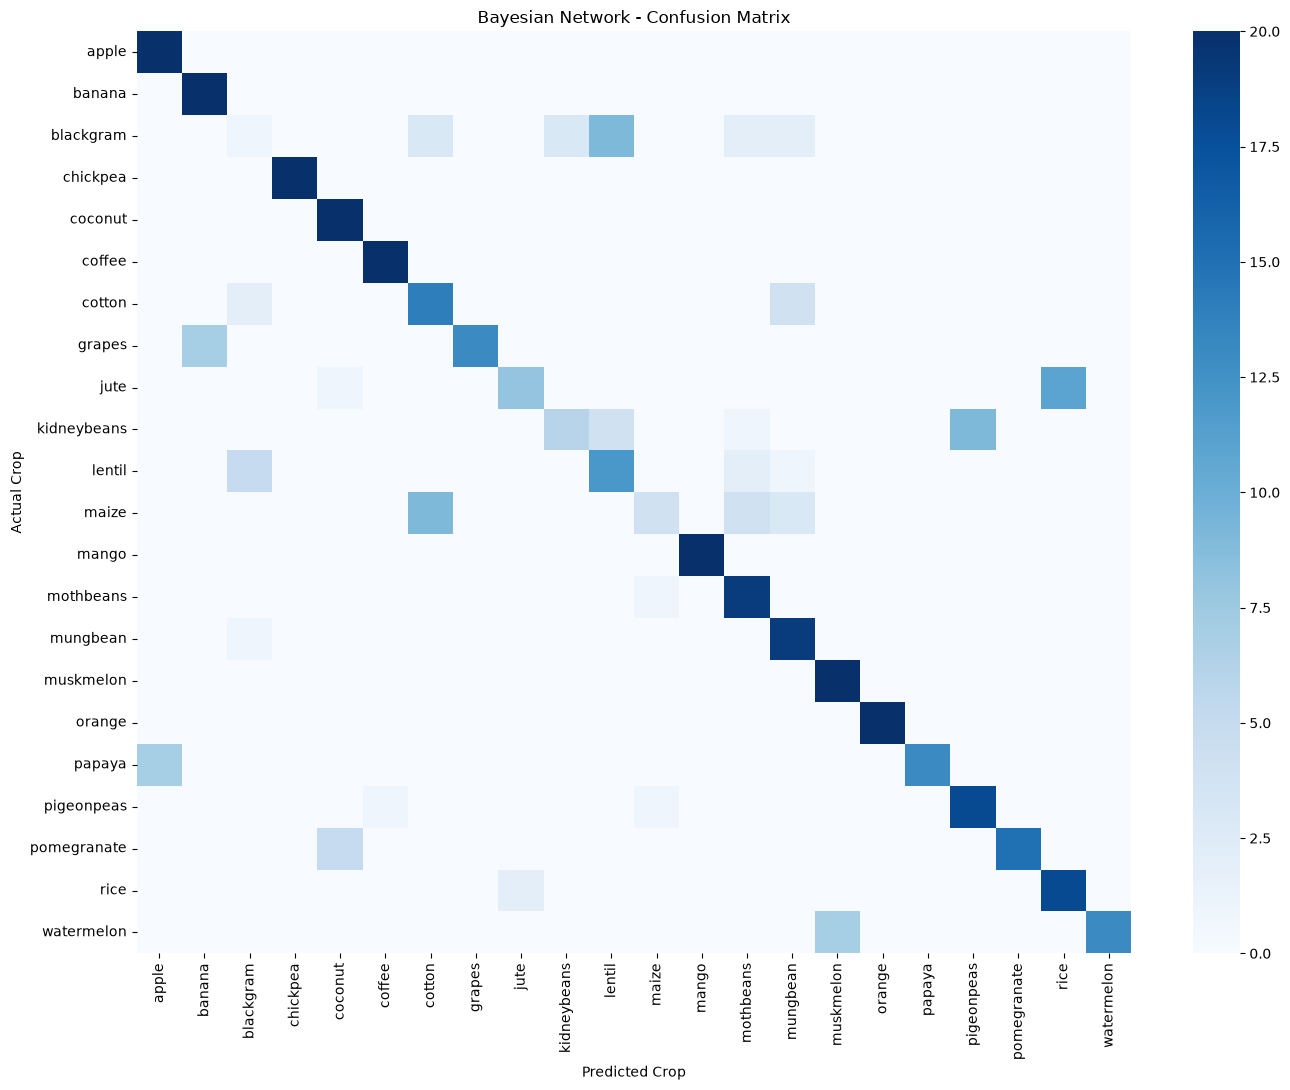

In [35]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Per-Class Performance:")
print(classification_report(y_true, y_pred, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=sorted(set(y_true)))
plt.figure(figsize=(14, 11))
sns.heatmap(cm, cmap='Blues', annot=False,
            xticklabels=sorted(set(y_true)),
            yticklabels=sorted(set(y_true)))
plt.title("Bayesian Network - Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


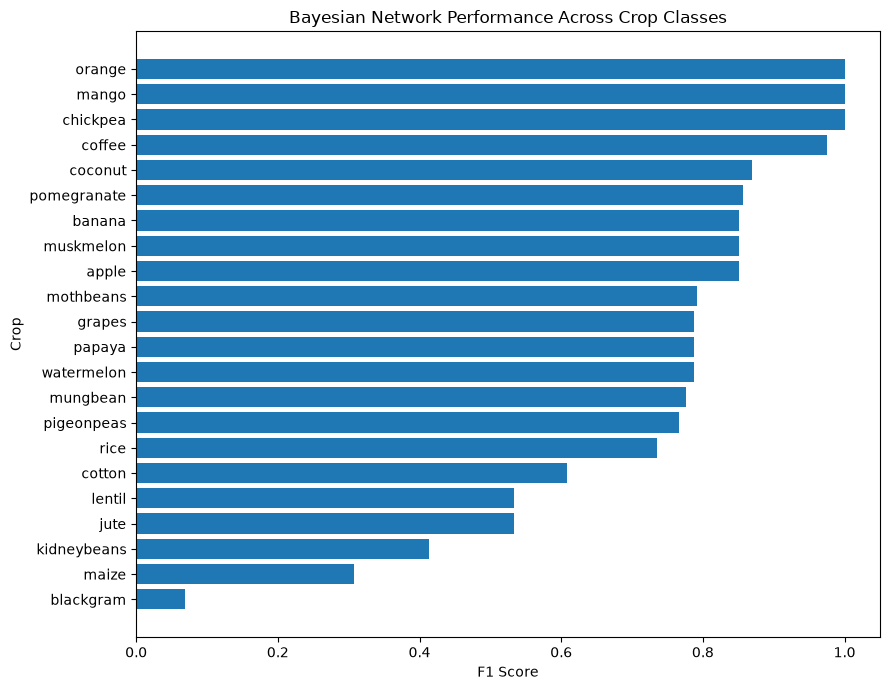

In [36]:


crop_names = sorted(set(y_true))

f1_scores = f1_score(
    y_true,
    y_pred,
    labels=crop_names,
    average=None
)

f1_df = pd.DataFrame({
    'Crop': crop_names,
    'F1 Score': f1_scores
}).sort_values('F1 Score')

plt.figure(figsize=(9, 7))

plt.barh(
    f1_df['Crop'],
    f1_df['F1 Score']
)

plt.xlabel("F1 Score")
plt.ylabel("Crop")
plt.title("Bayesian Network Performance Across Crop Classes")

plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

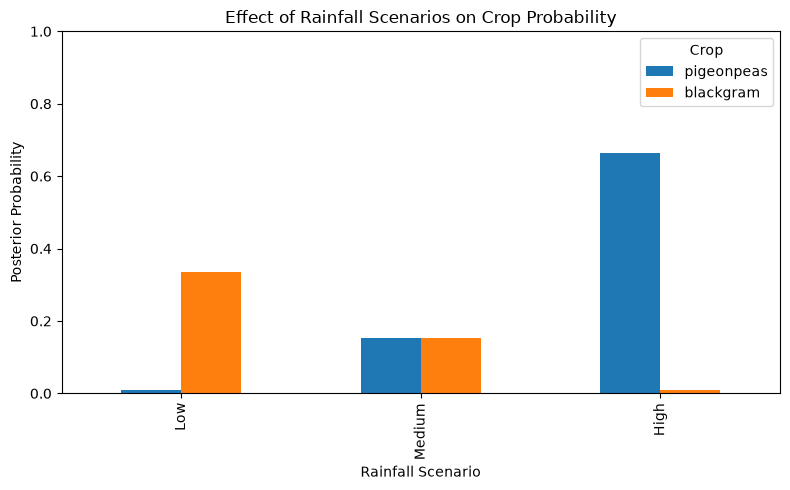

In [37]:
scenario_plot = rainfall_scenarios.loc[
    ['pigeonpeas', 'blackgram']
].T

scenario_plot.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel("Rainfall Scenario")
plt.ylabel("Posterior Probability")
plt.title("Effect of Rainfall Scenarios on Crop Probability")

plt.ylim(0, 1)

plt.legend(title="Crop")
plt.tight_layout()
plt.show()